In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import os

IMAGE_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/data/chest-xray-masks-and-labels/Lung Segmentation/CXR_png"

MASK_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/data/chest-xray-masks-and-labels/Lung Segmentation/masks"

print("Number of X-rays:", len(os.listdir(IMAGE_DIR)))
print("Number of masks:", len(os.listdir(MASK_DIR)))

print("\nFirst 5 images:")
print(os.listdir(IMAGE_DIR)[:5])

print("\nFirst 5 masks:")
print(os.listdir(MASK_DIR)[:5])

Number of X-rays: 289
Number of masks: 704

First 5 images:
['CHNCXR_0001_0.png', 'CHNCXR_0002_0.png', 'CHNCXR_0003_0.png', 'CHNCXR_0004_0.png', 'CHNCXR_0005_0.png']

First 5 masks:
['CHNCXR_0001_0_mask.png', 'CHNCXR_0002_0_mask.png', 'CHNCXR_0003_0_mask.png', 'CHNCXR_0004_0_mask.png', 'CHNCXR_0005_0_mask.png']


In [ ]:
import os

IMAGE_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/data/chest-xray-masks-and-labels/Lung Segmentation/CXR_png"
MASK_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/data/chest-xray-masks-and-labels/Lung Segmentation/masks"

images = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".png")
]

valid_pairs = []
missing_masks = []

for image_name in images:

    base_name = os.path.splitext(image_name)[0]

    mask_name = base_name + "_mask.png"

    mask_path = os.path.join(MASK_DIR, mask_name)

    if os.path.exists(mask_path):
        valid_pairs.append((image_name, mask_name))
    else:
        missing_masks.append(image_name)


print("Total X-rays:", len(images))
print("Total masks in folder:", len([
    f for f in os.listdir(MASK_DIR)
    if f.lower().endswith(".png")
]))

print("Valid image-mask pairs:", len(valid_pairs))
print("X-rays without masks:", len(missing_masks))

print("\nFirst 5 valid pairs:")
for image, mask in valid_pairs[:5]:
    print(image, " <--> ", mask)

Total X-rays: 289
Total masks in folder: 704
Valid image-mask pairs: 242
X-rays without masks: 47

First 5 valid pairs:
CHNCXR_0001_0.png  <-->  CHNCXR_0001_0_mask.png
CHNCXR_0002_0.png  <-->  CHNCXR_0002_0_mask.png
CHNCXR_0003_0.png  <-->  CHNCXR_0003_0_mask.png
CHNCXR_0004_0.png  <-->  CHNCXR_0004_0_mask.png
CHNCXR_0005_0.png  <-->  CHNCXR_0005_0_mask.png


In [ ]:
import os
import random

# Reproducibility
SEED = 42
random.seed(SEED)

# Shuffle the valid image-mask pairs
pairs = valid_pairs.copy()
random.shuffle(pairs)

# Total pairs
total = len(pairs)

# 80% training
train_end = int(0.80 * total)

# Next 10% validation
val_end = int(0.90 * total)

train_pairs = pairs[:train_end]
val_pairs = pairs[train_end:val_end]
test_pairs = pairs[val_end:]

print("Total pairs:", total)
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

Total pairs: 242
Training pairs: 193
Validation pairs: 24
Testing pairs: 25


In [ ]:
SPLIT_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/splits"

os.makedirs(SPLIT_DIR, exist_ok=True)

def save_split(filename, pairs):
    path = os.path.join(SPLIT_DIR, filename)

    with open(path, "w") as f:
        for image_name, mask_name in pairs:
            f.write(f"{image_name},{mask_name}\n")

    print("Saved:", path)

save_split("train_files.txt", train_pairs)
save_split("val_files.txt", val_pairs)
save_split("test_files.txt", test_pairs)

Saved: /content/drive/MyDrive/MAJOR_PROJECT/splits/train_files.txt
Saved: /content/drive/MyDrive/MAJOR_PROJECT/splits/val_files.txt
Saved: /content/drive/MyDrive/MAJOR_PROJECT/splits/test_files.txt


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from PIL import Image
import numpy as np
import os
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


In [ ]:
IMAGE_SIZE = 512


class LungSegmentationDataset(Dataset):

    def __init__(self, pairs, image_dir, mask_dir, train=False):

        self.pairs = pairs
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        image_name, mask_name = self.pairs[idx]

        # Load X-ray
        image_path = os.path.join(self.image_dir, image_name)
        image = Image.open(image_path).convert("L")

        # Load mask
        mask_path = os.path.join(self.mask_dir, mask_name)
        mask = Image.open(mask_path).convert("L")

        # Resize
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )

        # Convert to numpy
        image = np.array(image, dtype=np.float32)
        mask = np.array(mask, dtype=np.float32)

        # Normalize image to [0,1]
        image = image / 255.0

        # Binary mask
        mask = (mask > 127).astype(np.float32)

        # Convert grayscale image to 3 channels
        image = np.stack([image, image, image], axis=0)

        # Convert mask to tensor
        mask = np.expand_dims(mask, axis=0)

        image = torch.tensor(image, dtype=torch.float32)
        mask = torch.tensor(mask, dtype=torch.float32)

        # Simple augmentation
        if self.train:

            if torch.rand(1).item() > 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])

        return image, mask

In [ ]:
train_dataset = LungSegmentationDataset(
    train_pairs,
    IMAGE_DIR,
    MASK_DIR,
    train=True
)

val_dataset = LungSegmentationDataset(
    val_pairs,
    IMAGE_DIR,
    MASK_DIR,
    train=False
)

test_dataset = LungSegmentationDataset(
    test_pairs,
    IMAGE_DIR,
    MASK_DIR,
    train=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 193
Validation samples: 24
Testing samples: 25


In [ ]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
image, mask = train_dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image range:", image.min().item(), "to", image.max().item())
print("Mask values:", torch.unique(mask))

Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image range: 0.0 to 1.0
Mask values: tensor([0., 1.])


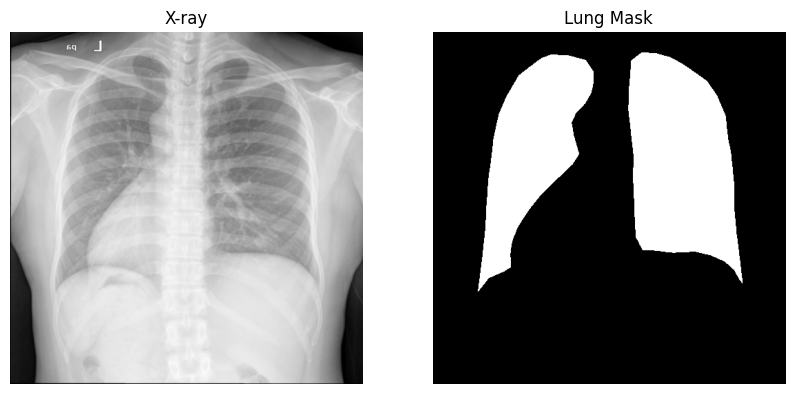

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image[0], cmap="gray")
plt.title("X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask[0], cmap="gray")
plt.title("Lung Mask")
plt.axis("off")

plt.show()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


# --------------------------------------------------
# ASPP - Atrous Spatial Pyramid Pooling
# --------------------------------------------------

class ASPP(nn.Module):

    def __init__(self, in_channels, out_channels=256):

        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        self.conv6 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=6,
                dilation=6,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        self.conv12 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=12,
                dilation=12,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        self.conv18 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=18,
                dilation=18,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Global average pooling branch
        self.global_pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, out_channels, 1, bias=False),
            nn.ReLU(inplace=True)
        )

        self.project = nn.Sequential(
            nn.Conv2d(
                out_channels * 5,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

    def forward(self, x):

        size = x.shape[-2:]

        feature1 = self.conv1(x)
        feature2 = self.conv6(x)
        feature3 = self.conv12(x)
        feature4 = self.conv18(x)

        feature5 = self.global_pool(x)

        feature5 = F.interpolate(
            feature5,
            size=size,
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [
                feature1,
                feature2,
                feature3,
                feature4,
                feature5
            ],
            dim=1
        )

        return self.project(x)


# --------------------------------------------------
# DeepLabV3+
# --------------------------------------------------

class DeepLabV3Plus(nn.Module):

    def __init__(self, num_classes=1):

        super().__init__()

        # ResNet-50 backbone
        backbone = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        # Low-level feature extraction
        self.layer0 = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool
        )

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # ASPP
        self.aspp = ASPP(
            in_channels=2048,
            out_channels=256
        )

        # Low-level feature projection
        self.low_level = nn.Sequential(
            nn.Conv2d(
                256,
                48,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(
                256 + 48,
                256,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                256,
                256,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # Final classifier
        self.classifier = nn.Conv2d(
            256,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        input_size = x.shape[-2:]

        # ResNet feature extraction
        x = self.layer0(x)

        low_level = self.layer1(x)

        x = self.layer2(low_level)
        x = self.layer3(x)
        x = self.layer4(x)

        # ASPP
        x = self.aspp(x)

        # Upsample ASPP features
        x = F.interpolate(
            x,
            size=low_level.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Process low-level features
        low_level = self.low_level(low_level)

        # Combine
        x = torch.cat(
            [x, low_level],
            dim=1
        )

        # Decoder
        x = self.decoder(x)

        # Final prediction
        x = self.classifier(x)

        # Restore original image size
        x = F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return x

In [ ]:
model = DeepLabV3Plus(num_classes=1)

model = model.to(device)

print("DeepLabV3+ model created successfully.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


DeepLabV3+ model created successfully.


In [ ]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.view(-1)
        targets = targets.view(-1)

        intersection = (probabilities * targets).sum()

        dice = (
            (2.0 * intersection + self.smooth)
            /
            (
                probabilities.sum()
                + targets.sum()
                + self.smooth
            )
        )

        return 1 - dice

In [ ]:
bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()

def combined_loss(logits, targets):

    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return bce + dice

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Optimizer: AdamW
Learning rate: 0.0001


In [ ]:
def calculate_metrics(logits, targets, threshold=0.5):

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities > threshold).float()

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    TP = (predictions * targets).sum().item()

    FP = (predictions * (1 - targets)).sum().item()

    FN = ((1 - predictions) * targets).sum().item()

    TN = ((1 - predictions) * (1 - targets)).sum().item()

    epsilon = 1e-7

    dice = (
        (2 * TP + epsilon)
        /
        (2 * TP + FP + FN + epsilon)
    )

    iou = (
        (TP + epsilon)
        /
        (TP + FP + FN + epsilon)
    )

    precision = (
        (TP + epsilon)
        /
        (TP + FP + epsilon)
    )

    recall = (
        (TP + epsilon)
        /
        (TP + FN + epsilon)
    )

    pixel_accuracy = (
        (TP + TN + epsilon)
        /
        (TP + TN + FP + FN + epsilon)
    )

    return dice, iou, precision, recall, pixel_accuracy

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape :", images.shape)
print("Mask shape  :", masks.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([4, 3, 512, 512])
Mask shape  : torch.Size([4, 1, 512, 512])
Output shape: torch.Size([4, 1, 512, 512])


In [ ]:
def train_one_epoch(model, loader, optimizer, device):

    model.train()

    running_loss = 0.0

    for images, masks in loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)


def validate_one_epoch(model, loader, device):

    model.eval()

    running_loss = 0.0

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)

            loss = combined_loss(outputs, masks)

            running_loss += loss.item()

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities > 0.5).float()

            predictions = predictions.view(-1)
            masks_flat = masks.view(-1)

            total_tp += (
                (predictions * masks_flat)
                .sum()
                .item()
            )

            total_fp += (
                (predictions * (1 - masks_flat))
                .sum()
                .item()
            )

            total_fn += (
                ((1 - predictions) * masks_flat)
                .sum()
                .item()
            )

            total_tn += (
                ((1 - predictions) * (1 - masks_flat))
                .sum()
                .item()
            )

    epsilon = 1e-7

    dice = (
        (2 * total_tp + epsilon)
        /
        (2 * total_tp + total_fp + total_fn + epsilon)
    )

    iou = (
        (total_tp + epsilon)
        /
        (total_tp + total_fp + total_fn + epsilon)
    )

    precision = (
        (total_tp + epsilon)
        /
        (total_tp + total_fp + epsilon)
    )

    recall = (
        (total_tp + epsilon)
        /
        (total_tp + total_fn + epsilon)
    )

    pixel_accuracy = (
        (total_tp + total_tn + epsilon)
        /
        (
            total_tp
            + total_tn
            + total_fp
            + total_fn
            + epsilon
        )
    )

    return (
        running_loss / len(loader),
        dice,
        iou,
        precision,
        recall,
        pixel_accuracy
    )

In [ ]:
import os

RESULTS_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/deeplab_results"

os.makedirs(RESULTS_DIR, exist_ok=True)

print("Results folder ready:")
print(RESULTS_DIR)

Results folder ready:
/content/drive/MyDrive/MAJOR_PROJECT/deeplab_results


In [ ]:
NUM_EPOCHS = 30

best_val_dice = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": [],
    "val_pixel_accuracy": []
}

# Folder to save results
RESULTS_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/deeplab_results"

os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "best_deeplabv3plus.pth"
)


for epoch in range(NUM_EPOCHS):

    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 60)

    # -------------------------
    # Training
    # -------------------------

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    # -------------------------
    # Validation
    # -------------------------

    (
        val_loss,
        val_dice,
        val_iou,
        val_precision,
        val_recall,
        val_pixel_accuracy
    ) = validate_one_epoch(
        model,
        val_loader,
        device
    )

    # Learning-rate scheduler
    scheduler.step(val_dice)

    # Store history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_pixel_accuracy"].append(
        val_pixel_accuracy
    )

    # Current learning rate
    current_lr = optimizer.param_groups[0]["lr"]

    print(f"Train Loss       : {train_loss:.4f}")
    print(f"Validation Loss  : {val_loss:.4f}")
    print(f"Validation Dice  : {val_dice:.4f}")
    print(f"Validation IoU   : {val_iou:.4f}")
    print(f"Validation Prec. : {val_precision:.4f}")
    print(f"Validation Recall: {val_recall:.4f}")
    print(f"Pixel Accuracy   : {val_pixel_accuracy:.4f}")
    print(f"Learning Rate    : {current_lr:.6f}")

    # -------------------------
    # Save best model
    # -------------------------

    if val_dice > best_val_dice:

        best_val_dice = val_dice

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            BEST_MODEL_PATH
        )

        print("✓ Best model saved!")

print("\nTraining completed.")
print("Best Validation Dice:", best_val_dice)
print("Model saved at:")
print(BEST_MODEL_PATH)


Epoch 1/30
Train Loss       : 0.0708
Validation Loss  : 0.1418
Validation Dice  : 0.9487
Validation IoU   : 0.9024
Validation Prec. : 0.9604
Validation Recall: 0.9373
Pixel Accuracy   : 0.9759
Learning Rate    : 0.000100
✓ Best model saved!

Epoch 2/30
Train Loss       : 0.0660
Validation Loss  : 0.1539
Validation Dice  : 0.9473
Validation IoU   : 0.8999
Validation Prec. : 0.9666
Validation Recall: 0.9287
Pixel Accuracy   : 0.9754
Learning Rate    : 0.000100

Epoch 3/30
Train Loss       : 0.0632
Validation Loss  : 0.1468
Validation Dice  : 0.9495
Validation IoU   : 0.9039
Validation Prec. : 0.9625
Validation Recall: 0.9369
Pixel Accuracy   : 0.9763
Learning Rate    : 0.000100
✓ Best model saved!

Epoch 4/30
Train Loss       : 0.0575
Validation Loss  : 0.1441
Validation Dice  : 0.9488
Validation IoU   : 0.9025
Validation Prec. : 0.9583
Validation Recall: 0.9394
Pixel Accuracy   : 0.9759
Learning Rate    : 0.000100

Epoch 5/30
Train Loss       : 0.0587
Validation Loss  : 0.1393
Validati